# Annotation Evaluation — Embedding Similarity

This notebook evaluates how well the LLM-generated event annotations match the human-annotated ground truth. It compares generated events against human annotations using sentence embedding cosine similarity, computes recall per combo, saves results to `Evaluations/`, and produces rankings and visualisations.

**Run order:** run cells top to bottom. Cells 1–2 define all helpers and only need to be run once per session. Cell 3 is the main evaluation pipeline. Cells 4–7 are for inspection and ranking and can be re-run freely.

> To install dependencies, uncomment and run Cell 0 once.

In [19]:
# !pip install sentence-transformers scikit-learn pandas seaborn matplotlib

### 1. Imports and configuration

Loads dependencies and sets directory paths. `SIMILARITY_THRESHOLD` controls the minimum cosine similarity for a generated event to be considered a match for a human annotation.

In [ ]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime, timezone
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings("ignore")

VIDEO_IDS        = [25, 26, 27, 28]
ANNOTATIONS_DIR  = Path("..", "Moment-Retrieval-and-Video-Summarization", "Annotations")
DESCRIPTIONS_DIR = Path("..", "Moment-Retrieval-and-Video-Summarization", "Descriptions")
EVAL_DIR         = Path("..", "Moment-Retrieval-and-Video-Summarization", "Evaluations")
EVAL_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5

embedder = SentenceTransformer("all-MiniLM-L6-v2")
print("Embedder loaded")

### 2. Core helpers

- `make_combo_key` — builds a canonical string key for a (vlm\_source, frame\_count, llm\_prompt) combination
- `load_human_annotations` — reads ground truth event descriptions from `Annotations/GroundTruthVideo{id}.txt`
- `evaluate_combo` — for a given set of generated events and human annotations, encodes both using `all-MiniLM-L6-v2` sentence embeddings, computes pairwise cosine similarity, and for each human annotation finds the best-matching generated event. An annotation is considered detected if similarity exceeds the threshold. Returns recall and average best similarity.
- `load_all_evals` — loads all saved evaluation results across all videos into a single DataFrame

In [ ]:
# Core helpers

def make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    return f"vlm={vlm_prompt_type}__frames={vlm_frame_count}__llm={llm_prompt_type}"


def load_human_annotations(video_id):
    txt_file = ANNOTATIONS_DIR / f"GroundTruthVideo{video_id}.txt"
    if not txt_file.exists():
        return []
    with open(txt_file, "r", encoding="utf-8") as f:
        lines = [l.strip() for l in f if l.strip()]
    if lines and lines[0].lower().startswith("annotation"):
        lines = lines[1:]
    return [line.split(',')[0] for line in lines]


def load_generated_events(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    json_file = DESCRIPTIONS_DIR / f"video_{video_id}.json"
    if not json_file.exists():
        return []
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)
    result = next(
        (r for r in data.get("llm_results", [])
         if r.get("prompt_type")    == llm_prompt_type
         and r.get("vlm_source")    == vlm_prompt_type
         and r.get("vlm_frame_count") == vlm_frame_count),
        None
    )
    return result.get("parsed_events", []) if result else []


def already_evaluated(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    eval_file = EVAL_DIR / f"video_{video_id}_eval_annot.json"
    if not eval_file.exists():
        return False
    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)
    key = make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type)
    return any(r["combo_key"] == key for r in data.get("evaluations", []))


def evaluate(human_annotations, generated_events, threshold=THRESHOLD):
    if not human_annotations or not generated_events:
        return None
    human_emb     = embedder.encode(human_annotations)
    generated_emb = embedder.encode(generated_events)
    sim_matrix    = cosine_similarity(human_emb, generated_emb)
    per_annotation = []
    detected = 0
    for i, human_event in enumerate(human_annotations):
        best_score     = float(sim_matrix[i].max())
        best_match_idx = int(sim_matrix[i].argmax())
        is_detected    = best_score >= threshold
        if is_detected:
            detected += 1
        per_annotation.append({
            "human_event": human_event,
            "best_match":  generated_events[best_match_idx],
            "score":       round(best_score, 4),
            "detected":    is_detected,
        })
    return {
        "per_annotation":      per_annotation,
        "similarity_matrix":   sim_matrix.tolist(),
        "num_human":           len(human_annotations),
        "num_generated":       len(generated_events),
        "detected":            detected,
        "missed":              len(human_annotations) - detected,
        "recall":              round(detected / len(human_annotations), 4),
        "avg_best_similarity": round(float(sim_matrix.max(axis=1).mean()), 4),
        "threshold":           threshold,
    }


def save_eval_result(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type,
                     eval_result, human_annotations, generated_events):
    eval_file = EVAL_DIR / f"video_{video_id}_eval_annot.json"
    data = {"video_id": video_id, "evaluations": []}
    if eval_file.exists():
        with open(eval_file, "r", encoding="utf-8") as f:
            data = json.load(f)
    data["evaluations"].append({
        "combo_key":         make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type),
        "vlm_prompt_type":   vlm_prompt_type,
        "vlm_frame_count":   vlm_frame_count,
        "llm_prompt_type":   llm_prompt_type,
        "timestamp":         datetime.now(timezone.utc).isoformat(),
        "threshold":         eval_result["threshold"],
        "human_annotations": human_annotations,
        "generated_events":  generated_events,
        "metrics":           {
            "num_human":           eval_result["num_human"],
            "num_generated":       eval_result["num_generated"],
            "detected":            eval_result["detected"],
            "missed":              eval_result["missed"],
            "recall":              eval_result["recall"],
            "avg_best_similarity": eval_result["avg_best_similarity"],
        },
        "per_annotation":    eval_result["per_annotation"],
        "similarity_matrix": eval_result["similarity_matrix"],
    })
    with open(eval_file, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)


def load_all_evals(video_ids=VIDEO_IDS):
    rows = []
    for video_id in video_ids:
        eval_file = EVAL_DIR / f"video_{video_id}_eval_annot.json"
        if not eval_file.exists():
            continue
        with open(eval_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        for e in data.get("evaluations", []):
            m = e["metrics"]
            rows.append({
                "video_id":        video_id,
                "vlm_prompt_type": e["vlm_prompt_type"],
                "vlm_frame_count": e["vlm_frame_count"],
                "llm_prompt_type": e["llm_prompt_type"],
                "combo_key":       e["combo_key"],
                "recall":          m["recall"],
                "avg_similarity":  m["avg_best_similarity"],
                "detected":        m["detected"],
                "missed":          m["missed"],
                "num_human":       m["num_human"],
                "num_generated":   m["num_generated"],
            })
    return pd.DataFrame(rows)

print("Helpers loaded")

Helpers loaded


### 3. Evaluation pipeline

Main loop — iterates over all videos and all LLM result combos found in `Descriptions/video_{id}.json`. For each (vlm\_source, frame\_count, llm\_prompt) combination, computes recall and average similarity against the human annotations and saves the result to `Evaluations/video_{id}_eval_annot.json`. Already-evaluated combos are skipped automatically.

Re-run this cell after adding new LLM results.

In [ ]:
#  Auto-evaluate all unevaluated combos

new_evals = 0
skipped   = 0

for video_id in VIDEO_IDS:
    json_file = DESCRIPTIONS_DIR / f"video_{video_id}.json"
    if not json_file.exists():
        print(f"  video_{video_id}: no descriptions JSON, skipping")
        continue

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    human_annotations = load_human_annotations(video_id)
    if not human_annotations:
        print(f"  video_{video_id}: no human annotations found, skipping")
        continue

    for r in data.get("llm_results", []):
        vlm_prompt_type = r.get("vlm_source")
        vlm_frame_count = r.get("vlm_frame_count")
        llm_prompt_type = r.get("prompt_type")
        generated_events = r.get("parsed_events", [])

        if not generated_events:
            continue

        if already_evaluated(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
            skipped += 1
            continue

        result = evaluate(human_annotations, generated_events)
        if result is None:
            continue

        save_eval_result(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type,
                         result, human_annotations, generated_events)
        new_evals += 1
        print(f"  ✅ video_{video_id} | vlm={vlm_prompt_type} | frames={vlm_frame_count} | "
              f"llm={llm_prompt_type} → recall={result['recall']:.1%}")

print(f"\nDone — {new_evals} new evaluations, {skipped} already done")


Done — 0 new evaluations, 96 already done


### 4. Rankings

Aggregates all evaluation results and ranks combos by average recall and similarity across all four videos. Prints the full ranking table and highlights the best-performing combination.

=== Combo rankings (avg across videos) ===

   vlm_prompt_type  vlm_frame_count llm_prompt_type  avg_recall  avg_similarity  n_videos
1             long               50         concise    0.275500        0.409325         4
2            short               50         concise    0.261100        0.424075         4
3            short               30        detailed    0.256050        0.425575         4
4            short               50        detailed    0.253775        0.435275         4
5           medium               12        detailed    0.251500        0.391050         4
6             long               50        detailed    0.247725        0.396325         4
7             long               30        detailed    0.228275        0.427150         4
8           medium               30        detailed    0.228275        0.411675         4
9             long               12        detailed    0.201500        0.397700         4
10            long               12         concise    0

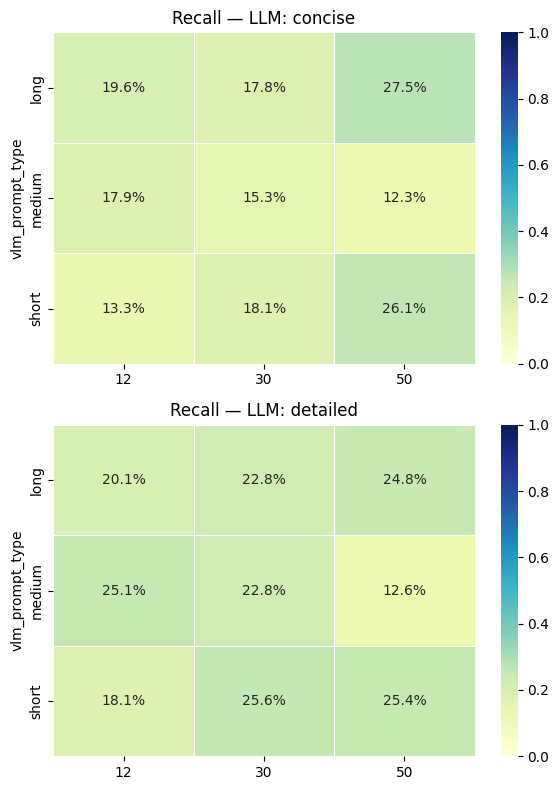

In [ ]:
# Overview & rankings

df = load_all_evals()

if df.empty:
    print("No evaluations yet — run Section 3 first")
else:
    # ── Rankings ──────────────────────────────────────────────
    ranked = (
        df.groupby(["vlm_prompt_type", "vlm_frame_count", "llm_prompt_type"])
        .agg(avg_recall=("recall","mean"), avg_similarity=("avg_similarity","mean"),
             n_videos=("video_id","count"))
        .reset_index()
        .sort_values(["avg_recall", "avg_similarity"], ascending=False)
    )
    ranked.index = range(1, len(ranked) + 1)
    print("=== Combo rankings (avg across videos) ===\n")
    print(ranked.to_string())
    print(f"\n🏆 Best: vlm={ranked.iloc[0]['vlm_prompt_type']} | "
          f"frames={ranked.iloc[0]['vlm_frame_count']} | "
          f"llm={ranked.iloc[0]['llm_prompt_type']}")

    # ── Recall heatmap per LLM type (vertical stack) ────────
    llm_types = df["llm_prompt_type"].unique()
    fig, axes = plt.subplots(len(llm_types), 1, figsize=(6, 4 * len(llm_types)))
    axes = np.atleast_1d(axes)
    for ax, llm_type in zip(axes, llm_types):
        pivot = df[df["llm_prompt_type"] == llm_type].pivot_table(
            index="vlm_prompt_type", columns="vlm_frame_count",
            values="recall", aggfunc="mean")
        sns.heatmap(pivot, ax=ax, annot=True, fmt=".1%",
                    cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5)
        ax.set_title(f"Recall — LLM: {llm_type}")
        ax.set_xlabel("")
    # plt.suptitle("Recall by VLM prompt × Frame count", y=0.92)
    plt.tight_layout()
    plt.show()

### 5. Best single result

Finds and prints the single best (video, combo) pair by recall then similarity — useful for identifying which specific video and configuration the model performed best on.

In [ ]:
if df.empty:
    print("No evaluations found. Run the evaluation cell first.")
else:
    # Best single evaluated example: highest recall, then highest similarity
    best = df.sort_values(["recall", "avg_similarity"], ascending=False).iloc[0]

    print("Best video + combination")
    print(f"  video_id        : {best['video_id']}")
    print(f"  vlm_prompt_type : {best['vlm_prompt_type']}")
    print(f"  vlm_frame_count : {best['vlm_frame_count']}")
    print(f"  llm_prompt_type  : {best['llm_prompt_type']}")
    print(f"  recall          : {best['recall']:.1%}")
    print(f"  avg_similarity  : {best['avg_similarity']:.4f}")
    print(f"  detected/missed  : {best['detected']}/{best['missed']}")
    print(f"  human/generated  : {best['num_human']}/{best['num_generated']}")

    eval_file = EVAL_DIR / f"video_{int(best['video_id'])}_eval_annot.json"
    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    key = make_combo_key(best["vlm_prompt_type"], int(best["vlm_frame_count"]), best["llm_prompt_type"])
    result = next(e for e in data["evaluations"] if e["combo_key"] == key)

    print("\nHuman annotations:")
    for i, a in enumerate(result["human_annotations"], 1):
        print(f"  H{i}: {a}")

    print("\nGenerated events:")
    for i, e in enumerate(result["generated_events"], 1):
        print(f"  G{i}: {e}")

    print("\nTop 5 combinations by average performance")
    top5 = (
        df.groupby(["video_id", "vlm_prompt_type", "vlm_frame_count", "llm_prompt_type"])
        .agg(avg_recall=("recall", "mean"), avg_similarity=("avg_similarity", "mean"))
        .reset_index()
        .sort_values(["avg_recall", "avg_similarity"], ascending=False)
        .head(5)
    )
    print(top5.to_string(index=False))

Best video + combination
  video_id        : 28
  vlm_prompt_type : long
  vlm_frame_count : 50
  llm_prompt_type  : detailed
  recall          : 70.0%
  avg_similarity  : 0.5147
  detected/missed  : 7/3
  human/generated  : 10/9

Human annotations:
  H1: A street in American city with a lot of people is shown
  H2: Police officers slowly drive through the street.
  H3: A police convoy slowly driving through the street
  H4: Crowd starts whistling and screaming when a truck with flags and people in it approaches
  H5: Crowd is chanting "go kings go" when a white truck with athletes in jerseys passes by
  H6: An armored police vehicle with athletes in jersey on the roof passes by to the shouts of the crowd
  H7: A white truck with a mascot in a trunk passes by to the shouts of the crowd
  H8: Someone in the crowd shout "Thank you for bringing the cup back."
  H9: A truck with large flags of a sports team logo passes by
  H10: Police and ambulance vehicles pass by

Generated events:
  G1

### 6. Best combo per video

For each video, shows the best-performing combo individually. Useful for understanding whether the same configuration generalises across videos or whether different videos favour different prompting strategies.

In [ ]:
if "df" not in globals() or df.empty:
    df = load_all_evals()

if df.empty:
    print("No evaluations found.")
else:
    best_per_video = (
        df.sort_values(["video_id", "recall", "avg_similarity"], ascending=[True, False, False])
          .groupby("video_id", as_index=False)
          .head(1)
          .reset_index(drop=True)
    )

    cols = [
        "video_id", "vlm_prompt_type", "vlm_frame_count", "llm_prompt_type",
        "recall", "avg_similarity", "detected", "missed", "num_human", "num_generated"
    ]
    print(best_per_video[cols].to_string(index=False))

 video_id vlm_prompt_type  vlm_frame_count llm_prompt_type  recall  avg_similarity  detected  missed  num_human  num_generated
       25            long               50         concise  0.3000          0.4220         3       7         10             10
       26           short               50         concise  0.4444          0.4472         4       5          9             10
       27            long               12         concise  0.2727          0.4018         3       8         11              7
       28            long               50        detailed  0.7000          0.5147         7       3         10              9


### 7. Inspector — drill into a specific combo

Prints a detailed breakdown for a specific (video, VLM prompt, frame count, LLM prompt) combination: per-annotation similarity scores, which annotations were detected vs missed, and overall recall.

**Configuration:** set `INSPECT_VIDEO_ID`, `INSPECT_VLM_PROMPT`, `INSPECT_VLM_FRAMES`, and `INSPECT_LLM_PROMPT` then re-run.

  video_28 | vlm=long | frames=50 | llm=detailed

  Human annotations : 10
  Generated events  : 9
  Detected          : 7 / 10
  Missed            : 3 / 10
  Recall            : 70.0%
  Avg similarity    : 0.51

  --- Per annotation ---
  ❌ (0.35) A street in American city with a lot of people is shown
         → A person waves an American flag high above the crowd, eliciting a strong reaction from the spectators.

  ✅ (0.56) Police officers slowly drive through the street.
         → Police motorcycles drive through traffic alongside police cars, maintaining order and control.

  ✅ (0.58) A police convoy slowly driving through the street
         → Police motorcycles drive through traffic alongside police cars, maintaining order and control.

  ✅ (0.57) Crowd starts whistling and screaming when a truck with flags and people in it approaches
         → A vehicle carrying a flag or banner drives by, prompting an enthusiastic cheer from the crowd.

  ❌ (0.43) Crowd is chanting "go kings

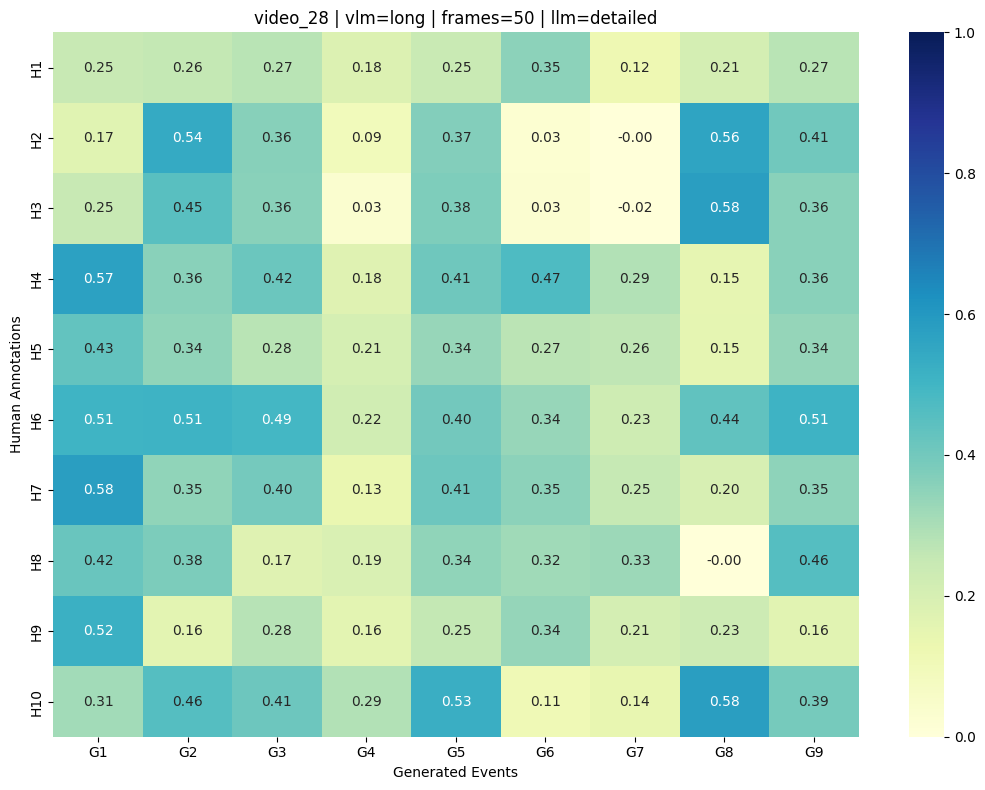

  Human annotations:
    H1: A street in American city with a lot of people is shown
    H2: Police officers slowly drive through the street.
    H3: A police convoy slowly driving through the street
    H4: Crowd starts whistling and screaming when a truck with flags and people in it approaches
    H5: Crowd is chanting "go kings go" when a white truck with athletes in jerseys passes by
    H6: An armored police vehicle with athletes in jersey on the roof passes by to the shouts of the crowd
    H7: A white truck with a mascot in a trunk passes by to the shouts of the crowd
    H8: Someone in the crowd shout "Thank you for bringing the cup back."
    H9: A truck with large flags of a sports team logo passes by
    H10: Police and ambulance vehicles pass by

  Generated events:
    G1: A vehicle carrying a flag or banner drives by, prompting an enthusiastic cheer from the crowd.
    G2: Police officers ride through traffic waving back at spectators, who respond with loud cheers.
    G3

In [ ]:
# Inspector: drill into any specific combo
# Change these 3 variables, then run the cell

INSPECT_VIDEO_ID       = 28
INSPECT_VLM_PROMPT     = "long"
INSPECT_VLM_FRAMES     = 50
INSPECT_LLM_PROMPT     = "detailed"

# ── Load ──────────────────────────────────────────────────────
eval_file = EVAL_DIR / f"video_{INSPECT_VIDEO_ID}_eval_annot.json"
if not eval_file.exists():
    print("No eval file found for this video — run Section 3 first")
else:
    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    key = make_combo_key(INSPECT_VLM_PROMPT, INSPECT_VLM_FRAMES, INSPECT_LLM_PROMPT)
    result = next((e for e in data["evaluations"] if e["combo_key"] == key), None)

    if not result:
        evaluated_keys = [e["combo_key"] for e in data["evaluations"]]
        print(f"Combo not found: {key}\n")
        print("Available combos for this video:")
        for k in evaluated_keys:
            print(f"  {k}")
    else:
        # ── Text report ───────────────────────────────────────
        m = result["metrics"]
        print(f"{'='*60}")
        print(f"  video_{INSPECT_VIDEO_ID} | vlm={INSPECT_VLM_PROMPT} | "
              f"frames={INSPECT_VLM_FRAMES} | llm={INSPECT_LLM_PROMPT}")
        print(f"{'='*60}\n")
        print(f"  Human annotations : {m['num_human']}")
        print(f"  Generated events  : {m['num_generated']}")
        print(f"  Detected          : {m['detected']} / {m['num_human']}")
        print(f"  Missed            : {m['missed']} / {m['num_human']}")
        print(f"  Recall            : {m['recall']:.1%}")
        print(f"  Avg similarity    : {m['avg_best_similarity']:.2f}\n")
        print("  --- Per annotation ---")
        for item in result["per_annotation"]:
            status = "✅" if item["detected"] else "❌"
            print(f"  {status} ({item['score']:.2f}) {item['human_event']}")
            print(f"         → {item['best_match']}\n")

        # ── Heatmap ───────────────────────────────────────────
        sim_matrix       = np.array(result["similarity_matrix"])
        human_labels     = [f"H{i+1}" for i in range(len(result["human_annotations"]))]
        generated_labels = [f"G{i+1}" for i in range(len(result["generated_events"]))]

        plt.figure(figsize=(max(8, len(generated_labels)*1.2),
                            max(5, len(human_labels)*0.8)))
        sns.heatmap(sim_matrix, xticklabels=generated_labels, yticklabels=human_labels,
                    annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
        plt.title(f"video_{INSPECT_VIDEO_ID} | vlm={INSPECT_VLM_PROMPT} | "
                  f"frames={INSPECT_VLM_FRAMES} | llm={INSPECT_LLM_PROMPT}")
        plt.xlabel("Generated Events")
        plt.ylabel("Human Annotations")
        plt.tight_layout()
        plt.show()

        print("  Human annotations:")
        for i, a in enumerate(result["human_annotations"], 1):
            print(f"    H{i}: {a}")
        print("\n  Generated events:")
        for i, e in enumerate(result["generated_events"], 1):
            print(f"    G{i}: {e}")

### 8–9. Raw output tables

Convenience cells for printing the full evaluation DataFrame and ranked summary to stdout — useful for copying numbers directly into the report.

In [ ]:
# df = load_all_evals()
# print(df[["video_id", "vlm_prompt_type", "vlm_frame_count",
#           "llm_prompt_type", "recall", "avg_similarity"]].to_string())

In [ ]:
# ranked = (
#     df.groupby(["vlm_prompt_type", "vlm_frame_count", "llm_prompt_type"])
#     .agg(avg_recall=("recall","mean"), avg_similarity=("avg_similarity","mean"))
#     .reset_index()
#     .sort_values(["avg_recall", "avg_similarity"], ascending=False)
# )
# print(ranked.to_string())